● Write a program to denoise the input image using adaptive median filter.
Input the initial window size and maximum size of window (Smax) from
the user. Compare the performance of median filter and adaptive median
filter, using the PSNR values.
● Write a program to threshold the image using Otsu's global threshold for
segmentation of input gray scale image.

Median Filter PSNR: 22.11692191653178
Adaptive Median Filter PSNR: 31.03378063604193


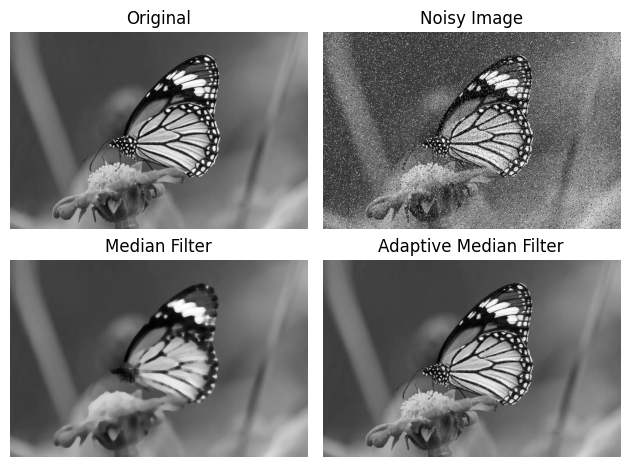

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('image_input.jpg', 0)

noisy = img.copy()
noise = np.random.rand(*img.shape)
noisy[noise < 0.05] = 0
noisy[noise > 0.95] = 255

Smin = int(input("Enter initial window size (odd number): "))
Smax = int(input("Enter maximum window size (odd number): "))

def adaptive_median(image, Smin, Smax):
    output = image.copy()
    pad = Smax // 2
    padded = cv2.copyMakeBorder(image, pad, pad, pad, pad,
                                cv2.BORDER_REFLECT)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):

            size = Smin

            while size <= Smax:
                r = size // 2
                window = padded[i+pad-r:i+pad+r+1,
                                j+pad-r:j+pad+r+1]

                zmin = np.min(window)
                zmax = np.max(window)
                zmed = np.median(window)
                zxy = padded[i+pad, j+pad]

                if zmin < zmed < zmax:
                    if zmin < zxy < zmax:
                        output[i, j] = zxy
                    else:
                        output[i, j] = zmed
                    break

                size += 2

            else:
                output[i, j] = zmed

    return output

median = cv2.medianBlur(noisy, Smin)

adaptive = adaptive_median(noisy, Smin, Smax)

psnr_median = cv2.PSNR(img, median)
psnr_adaptive = cv2.PSNR(img, adaptive)

print("Median Filter PSNR:", psnr_median)
print("Adaptive Median Filter PSNR:", psnr_adaptive)

titles = ['Original', 'Noisy Image', 'Median Filter',
          'Adaptive Median Filter']

images = [img, noisy, median, adaptive]

for i in range(4):
    plt.subplot(2, 2, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

Otsu Threshold Value: 0.0
Otsu Threshold Value: 108.0


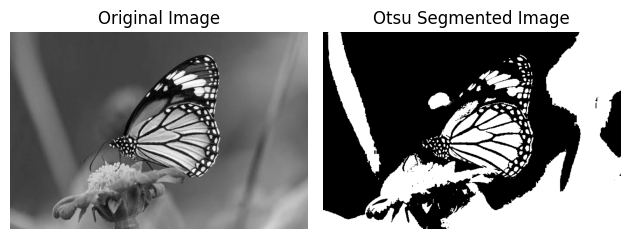

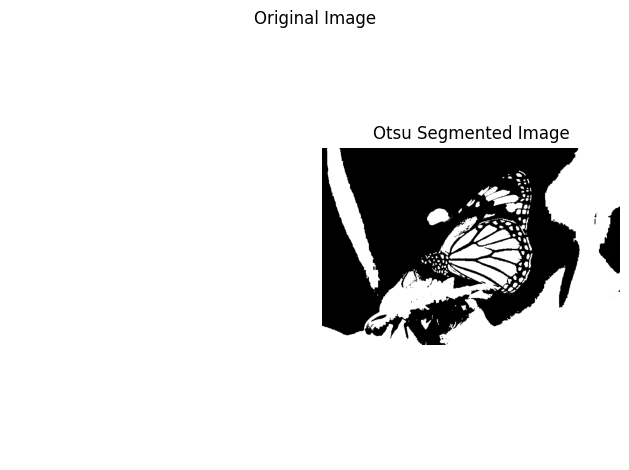

In [6]:
import cv2
import os
import matplotlib.pyplot as plt

img = cv2.imread('input.jpg', 0)

threshold, result = cv2.threshold(
    img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Otsu Threshold Value:", threshold)

plt.subplot(1, 2, 1)
import matplotlib.pyplot as plt

image_path = r"image_input.jpg"

if not os.path.isfile(image_path):
    raise FileNotFoundError(
        f"Could not find '{image_path}'. Place input.jpg in the notebook's current directory."
    )

img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if img is None:
    raise ValueError(
        f"OpenCV could not read '{image_path}'. Check that the file is a valid image."
    )

threshold, result = cv2.threshold(
    img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Otsu Threshold Value:", threshold)

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(result, cmap="gray")
plt.title("Otsu Segmented Image")
plt.axis("off")

plt.tight_layout()
plt.show()
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(result, cmap='gray')
plt.title('Otsu Segmented Image')
plt.axis('off')

plt.tight_layout()
plt.show()